# Fase 5 - Evaluación

Se cargan los seis pipelines persistidos en `Modelos/`, se comparan en validación y se evalúan con los **datos de generalización** (test ciego, nunca utilizado para entrenar ni seleccionar).

## 5.1 Carga de modelos y datos

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

ROOT = Path.cwd().resolve()
while not (ROOT / "Data" / "bank-full.csv").is_file() and ROOT.parent != ROOT:
    ROOT = ROOT.parent
DATA_PATH = ROOT / "Data" / "bank-full.csv"
MODELS_DIR = ROOT / "Modelos"

import json
import joblib
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv(DATA_PATH, sep=";").drop_duplicates().reset_index(drop=True)
for col in df.select_dtypes(include=["object", "string"]).columns:
    df[col] = df[col].str.strip()
df["y"] = df["y"].map({"no": 0, "yes": 1}).astype("int8")

POST_CONTACT = ["duration", "campaign", "day", "month", "contact"]
X = df.drop(columns=["y"] + POST_CONTACT)
y = df["y"]

X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=42)
print("Train:", X_train.shape, "| Validacion:", X_val.shape, "| Test ciego:", X_test.shape)

meta = json.loads((MODELS_DIR / "metadata.json").read_text(encoding="utf-8"))
modelos = {nombre: joblib.load(MODELS_DIR / archivo) for nombre, archivo in meta["models"].items()}
print("Modelos cargados:", list(modelos))

Train: (27126, 11) | Validacion: (9042, 11) | Test ciego: (9043, 11)
Modelos cargados: ['Iteracion 1 | Regresion logistica', 'Iteracion 2 | Regresion logistica', 'Iteracion 1 | Arbol de decision', 'Iteracion 2 | Arbol de decision', 'Iteracion 1 | Random Forest', 'Iteracion 2 | Random Forest']


## 5.2 Comparativa de iteraciones: validación vs. test ciego

In [2]:
from sklearn.metrics import (accuracy_score, average_precision_score, f1_score,
                             precision_score, recall_score, roc_auc_score)

def evaluar(nombre, modelo, X_eval, y_eval):
    pred = modelo.predict(X_eval)
    proba = modelo.predict_proba(X_eval)[:, 1]
    return {"Modelo": nombre,
            "Accuracy": accuracy_score(y_eval, pred),
            "Precision": precision_score(y_eval, pred, zero_division=0),
            "Recall": recall_score(y_eval, pred, zero_division=0),
            "F1": f1_score(y_eval, pred, zero_division=0),
            "ROC-AUC": roc_auc_score(y_eval, proba),
            "PR-AUC": average_precision_score(y_eval, proba)}

resultados = []

val = pd.DataFrame([evaluar(n, m, X_val, y_val) for n, m in modelos.items()]).set_index("Modelo").round(4)
test = pd.DataFrame([evaluar(n, m, X_test, y_test) for n, m in modelos.items()]).set_index("Modelo").round(4)
print("VALIDACION"); display(val)
print("TEST CIEGO (generalizacion)"); display(test)
(test - val).round(4)[["Recall", "F1", "ROC-AUC"]].rename(columns=lambda c: f"Delta {c}")

VALIDACION


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Modelo,,,,,,
Iteracion 1 | Regresion logistica,0.8943,0.6962,0.1711,0.2747,0.7210,0.3585
Iteracion 2 | Regresion logistica,0.7042,0.2243,0.6219,0.3297,0.7233,0.3540
Iteracion 1 | Arbol de decision,0.8194,0.2586,0.2911,0.2739,0.5890,0.1584
Iteracion 2 | Arbol de decision,0.8562,0.3929,0.4197,0.4059,0.7211,0.3462
Iteracion 1 | Random Forest,0.8952,0.7148,0.1730,0.2785,0.7473,0.4059
Iteracion 2 | Random Forest,0.8131,0.3205,0.5331,0.4003,0.7445,0.3986


TEST CIEGO (generalizacion)


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Modelo,,,,,,
Iteracion 1 | Regresion logistica,0.8936,0.6860,0.1673,0.2690,0.7199,0.3462
Iteracion 2 | Regresion logistica,0.6956,0.2166,0.6125,0.3201,0.7212,0.3446
Iteracion 1 | Arbol de decision,0.8195,0.2500,0.2713,0.2602,0.5813,0.1534
Iteracion 2 | Arbol de decision,0.8536,0.3800,0.3979,0.3887,0.7108,0.3325
Iteracion 1 | Random Forest,0.8937,0.6980,0.1616,0.2625,0.7384,0.3807
Iteracion 2 | Random Forest,0.8073,0.3064,0.5123,0.3834,0.7343,0.3760


,Delta Recall,Delta F1,Delta ROC-AUC
Modelo,,,
Iteracion 1 | Regresion logistica,-0.0038,-0.0057,-0.0011
Iteracion 2 | Regresion logistica,-0.0094,-0.0096,-0.0021
Iteracion 1 | Arbol de decision,-0.0198,-0.0137,-0.0077
Iteracion 2 | Arbol de decision,-0.0218,-0.0172,-0.0103
Iteracion 1 | Random Forest,-0.0114,-0.0160,-0.0089
Iteracion 2 | Random Forest,-0.0208,-0.0169,-0.0102


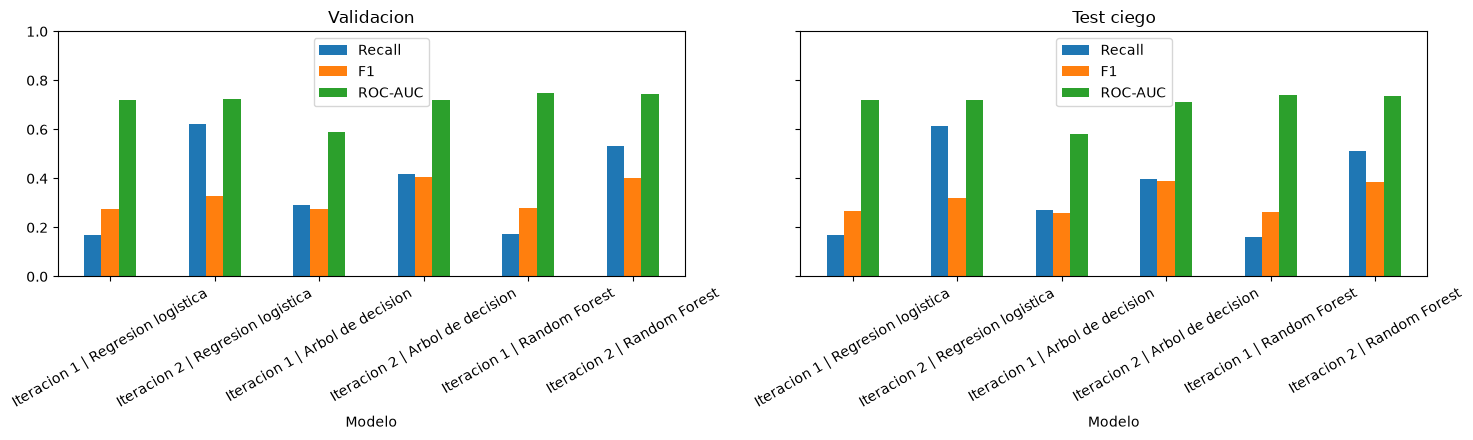

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
val[["Recall", "F1", "ROC-AUC"]].plot(kind="bar", ax=axes[0], title="Validacion")
test[["Recall", "F1", "ROC-AUC"]].plot(kind="bar", ax=axes[1], title="Test ciego")
for ax in axes: ax.set_ylim(0, 1); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

## 5.3 Curvas ROC en test ciego

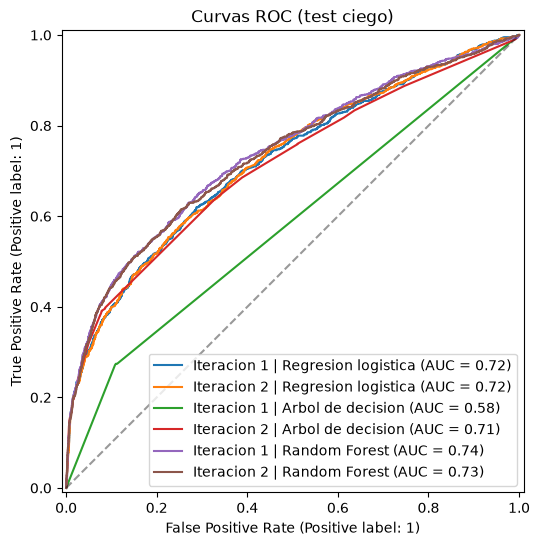

In [4]:
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(7, 6))
for nombre, modelo in modelos.items():
    RocCurveDisplay.from_predictions(y_test, modelo.predict_proba(X_test)[:, 1], name=nombre, ax=ax)
ax.plot([0, 1], [0, 1], "k--", alpha=.4); ax.set_title("Curvas ROC (test ciego)")
plt.show()

## 5.4 Selección del mejor modelo
El modelo recomendado se elige **solo con validación** (F1, desempate por Recall y ROC-AUC) entre los modelos de la Iteración 2, sin mirar el test.

In [5]:
candidatos = val.loc[[n for n in val.index if n.startswith("Iteracion 2")]]
mejor = candidatos.sort_values(["F1", "Recall", "ROC-AUC"], ascending=False).index[0]
print("Modelo seleccionado:", mejor, "| coincide con metadata:", mejor == meta["selected_model"])
display(pd.DataFrame({"Validacion": val.loc[mejor], "Test ciego": test.loc[mejor]}))

Modelo seleccionado: Iteracion 2 | Arbol de decision | coincide con metadata: True


,Validacion,Test ciego
Accuracy,0.8562,0.8536
Precision,0.3929,0.3800
Recall,0.4197,0.3979
F1,0.4059,0.3887
ROC-AUC,0.7211,0.7108
PR-AUC,0.3462,0.3325


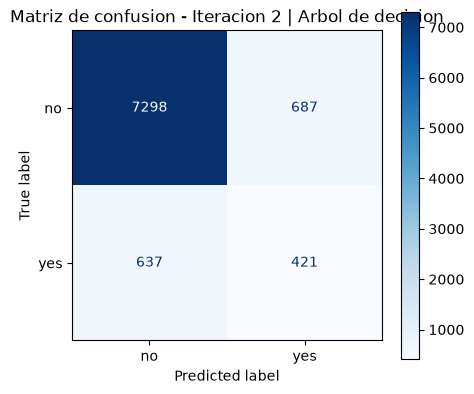

In [6]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay.from_estimator(modelos[mejor], X_test, y_test, display_labels=["no", "yes"],
                                      cmap="Blues", values_format="d", ax=ax)
ax.set_title(f"Matriz de confusion - {mejor}"); plt.show()

## 5.5 Importancia de variables y recomendaciones de negocio

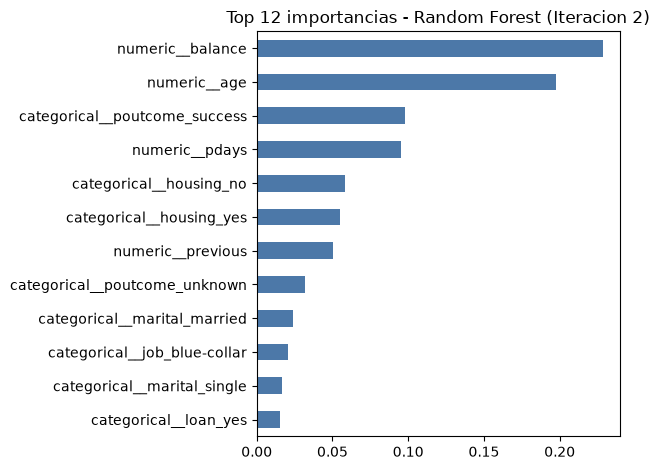

In [7]:
import numpy as np

pipe = modelos["Iteracion 2 | Random Forest"]
nombres = pipe.named_steps["preprocessing"].get_feature_names_out()
nombres = nombres[pipe.named_steps["selection"].get_support()]
imp = pd.Series(pipe.named_steps["classifier"].feature_importances_, index=nombres).sort_values(ascending=False)
imp.head(12).iloc[::-1].plot(kind="barh", color="#4C78A8", title="Top 12 importancias - Random Forest (Iteracion 2)")
plt.tight_layout(); plt.show()

## 5.6 Revisión frente a los criterios de la Fase 1

In [8]:
crit = test.loc[["Iteracion 2 | Random Forest", "Iteracion 2 | Arbol de decision", "Iteracion 2 | Regresion logistica"], ["Recall", "ROC-AUC"]].copy()
crit["Recall >= 0.50"] = crit["Recall"] >= 0.50
crit["ROC-AUC >= 0.70"] = crit["ROC-AUC"] >= 0.70
crit

,Recall,ROC-AUC,Recall >= 0.50,ROC-AUC >= 0.70
Modelo,,,,
Iteracion 2 | Random Forest,0.5123,0.7343,True,True
Iteracion 2 | Arbol de decision,0.3979,0.7108,False,True
Iteracion 2 | Regresion logistica,0.6125,0.7212,True,True


### Interpretación
- **Generalización:** las métricas de test son muy cercanas a las de validación (diferencias ≲ 0,02), sin señales de sobreajuste en los modelos de la Iteración 2.
- **Mejor modelo recomendado:** el **Árbol de Decisión de la Iteración 2** (F1 ≈ 0,41 en validación y ≈ 0,39 en test; Recall ≈ 0,40; ROC-AUC ≈ 0,71). Es el mejor equilibrio entre Precision y Recall y el artefacto más liviano e interpretable.
- **Criterios de negocio:** el **Random Forest balanceado** (Recall ≈ 0,51; ROC-AUC ≈ 0,73) y la **regresión logística balanceada** (Recall ≈ 0,61; ROC-AUC ≈ 0,72) superan ambos umbrales; el árbol cumple ROC-AUC pero no Recall (≈ 0,40). Sin embargo, la regresión logística lo logra con Precision muy baja (≈ 0,22: ~4 de cada 5 contactos serían falsos positivos). Por eso, si la prioridad es capturar suscriptores, el Random Forest o la regresión logística balanceados son alternativas; si se busca equilibrio, el árbol.
- **Limitación:** con solo variables previas al contacto la capacidad predictiva es moderada (ROC-AUC ≈ 0,72-0,74); los modelos sirven para **priorizar** clientes, no para decidir de forma automática.
- **Recomendación:** validar mediante un piloto controlado (grupo priorizado vs. aleatorio) y monitorear la deriva de datos antes de producción.

## Checklist Fase 5
- [x] Comparación Iteración 1 vs. 2
- [x] Evaluación con datos de generalización
- [x] Selección del mejor modelo con justificación
- [x] Revisión frente a los criterios de negocio